# Redshift evolution of the IGM

The four IGM features of astrodatapy, read with `astrodatapy.evolution`:

| Feature | Quantity | Returned in |
|---|---|---|
| `IGM_Emissivity` | ionizing emissivity $\dot{N}_{\rm ion}$ | s$^{-1}$ cMpc$^{-3}$ |
| `IGM_Gamma` | H I photoionization rate $\Gamma_{\rm HI}$ | **$10^{-12}$ s$^{-1}$** |
| `IGM_MFP` | mean free path of ionizing photons at 912 A, $\lambda_{\rm mfp}$ | **proper** Mpc |
| `IGM_T0` | temperature at the mean density, $T_0$ | K |

Each dataset is one paper. Observations are drawn as points, with the redshift bin as the
x error bar and arrows for upper/lower limits; **simulation (model) curves** (`DataType` =
`data_sim`) are drawn as lines and marked "(simulation)" in the legends. Error bars are 1$\sigma$
unless the legend says otherwise. The data files keep
the published units; `info.txt` of each feature says how they are converted (h, comoving vs
proper, log, normalisation).

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astrodatapy.evolution import evolution

h = 0.6751   # Hubble parameter to convert the data to (Planck 2015, as in combine.ipynb)
plt.rcParams.update({'font.size': 11})

## The datasets

In [2]:
rows = []
for feature in ['IGM_Emissivity', 'IGM_Gamma', 'IGM_MFP', 'IGM_T0']:
    obs = evolution(feature, quiet=True, h=h)
    for name, row in obs.target_observation.iterrows():
        z = row['Data'][:, 0]
        rows.append(dict(feature=feature, dataset=name, type=row['DataType'], method=row['Method'],
                         z_min=z.min(), z_max=z.max(), points=len(z),
                         upper_limits=int(row['ULimit'].sum()), lower_limits=int(row['LLimit'].sum()),
                         bibcode=obs.info.loc[name, 'Bibliographic']))
pd.set_option('display.max_rows', 200)
pd.DataFrame(rows)

,feature,dataset,type,method,z_min,z_max,points,upper_limits,lower_limits,bibcode
0,IGM_Emissivity,Gaikwad2023,data,Gamma_and_MFP,4.9000,6.0000,12,0,0,2023MNRAS.525.4093G
1,IGM_Emissivity,Bouwens2015,data,reionization_history_fit,6.0000,15.0000,10,0,0,2015ApJ...811..140B
2,IGM_Emissivity,Becker2013,data,Gamma_and_MFP,2.4000,4.7500,4,0,0,2013MNRAS.436.1023B
3,IGM_Emissivity,Becker2021,data,Gamma_and_MFP,5.1000,6.0000,2,0,0,2021MNRAS.508.1853B
4,IGM_Emissivity,Kulkarni2019_Sherwood,data_sim,RT_post-processing_calibrated,3.9996,11.9187,50,0,0,2019MNRAS.485L..24K
5,IGM_Emissivity,Keating2020_Sherwood,data_sim,RT_post-processing_calibrated,3.9999,11.6328,30,0,0,2020MNRAS.491.1736K
6,IGM_Emissivity,Cain2021_Rapid,data_sim,RT_post-processing_calibrated,4.4040,12.0000,95,0,0,2021ApJ...917L..37C
7,IGM_Emissivity,Cain2024_FlexRT,data_sim,RT_post-processing_calibrated,4.5000,12.0038,100,0,0,2024MNRAS.531.1951C
8,IGM_Emissivity,Ocvirk2021_CUDATON,data_sim,RHD_simulation,3.9994,12.0016,14,0,0,2021MNRAS.507.6108O
9,IGM_Emissivity,Yeh2023_THESAN1,data_sim,RHD_simulation,5.5118,12.9983,67,0,0,2023MNRAS.520.2757Y


In [3]:
markers = ['o', 's', '^', 'v', 'D', 'p', 'h', '<', '>', '*', 'P', 'X', 'd', 'H', '8']
obs_colors = plt.cm.tab20(np.linspace(0, 1, 20))
sim_styles = ['-', '--', '-.', ':', (0, (5, 1)), (0, (3, 1, 1, 1, 1, 1)), (0, (1, 1))]
sim_colors = ['k', '#8c510a', '#01665e', '#762a83', '#b2182b', '#2166ac', '#4d4d4d']
# observations whose error bars are not 1 sigma (see the headers of their data files)
error_notes = {'Becker2011': '2$\sigma$ errors', 'DAloisio2018': 'errors not 1$\sigma$'}

def plot_feature(feature, ylabel, yscale='linear', yfactor=1.0, xlim=None, ylim=None, h=h):
    """Plot every dataset of an IGM feature: observations as points, simulations as lines."""
    obs = evolution(feature, quiet=True, h=h)
    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    i_obs = i_sim = 0
    for name, row in obs.target_observation.iterrows():
        d = row['Data'].copy()
        d[:, 3:6] *= yfactor
        z, zhi, zlo, y, yhi, ylo = d.T
        if row['DataType'] == 'data_sim':
            ax.plot(z, y, ls=sim_styles[i_sim % len(sim_styles)], color=sim_colors[i_sim % len(sim_colors)], lw=1.5,
                    label='%s (simulation)' % name)
            i_sim += 1
            continue
        color, marker = obs_colors[(2 * i_obs) % 20 + (i_obs // 10) % 2], markers[i_obs % len(markers)]
        i_obs += 1
        lim = row['ULimit'] | row['LLimit']
        xerr = [z - zlo, zhi - z]
        ax.errorbar(z[~lim], y[~lim], xerr=[e[~lim] for e in xerr], yerr=[y[~lim] - ylo[~lim], yhi[~lim] - y[~lim]],
                    fmt=marker, color=color, mfc='white', ms=6, capsize=2, elinewidth=1,
                    label=name + (' (%s)' % error_notes[name] if name in error_notes else ''))
        for flag, kw in ((row['ULimit'], dict(uplims=True)), (row['LLimit'], dict(lolims=True))):
            if flag.any():
                arrow = 0.25 * y[flag] if yscale == 'log' else 0.1 * (ylim[1] - ylim[0] if ylim else np.ptp(y) or 1.0)
                ax.errorbar(z[flag], y[flag], xerr=[e[flag] for e in xerr], yerr=arrow, fmt=marker, color=color,
                            mfc='white', ms=6, capsize=2, elinewidth=1, **kw)
    ax.set_yscale(yscale)
    ax.set_xlabel('redshift')
    ax.set_ylabel(ylabel)
    if xlim: ax.set_xlim(xlim)
    if ylim: ax.set_ylim(ylim)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1.0), fontsize=9, frameon=False)
    ax.set_title('%s (h = %.4f)' % (feature, h), fontsize=11)
    fig.tight_layout()
    return fig, ax

## Ionizing emissivity

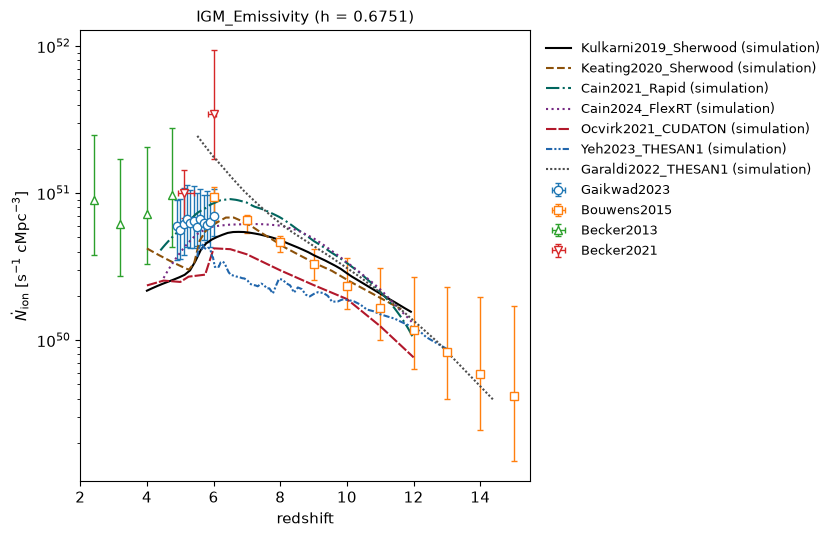

In [4]:
plot_feature('IGM_Emissivity', r'$\dot{N}_{\rm ion}$ [s$^{-1}$ cMpc$^{-3}$]', yscale='log', xlim=(2, 15.5));

## H I photoionization rate (in $10^{-12}$ s$^{-1}$)

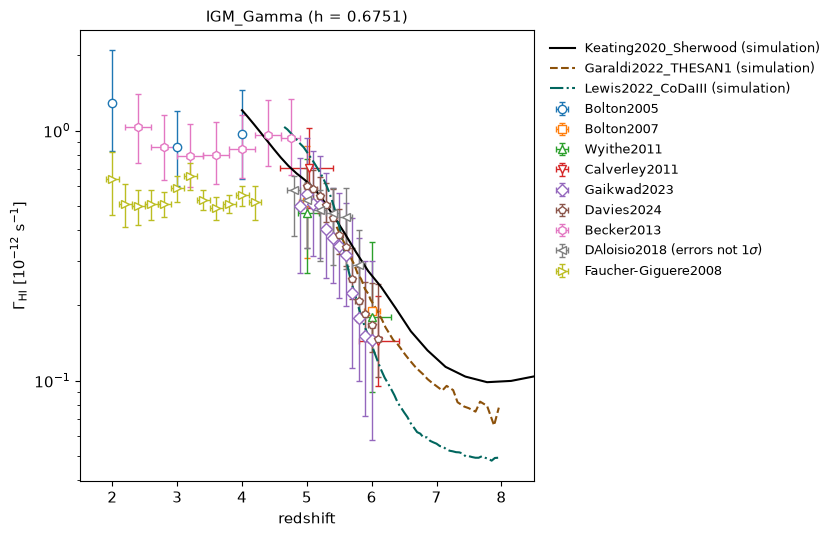

In [5]:
plot_feature('IGM_Gamma', r'$\Gamma_{\rm HI}$ [$10^{-12}$ s$^{-1}$]', yscale='log', xlim=(1.5, 8.5));

## Mean free path of ionizing photons (proper Mpc)

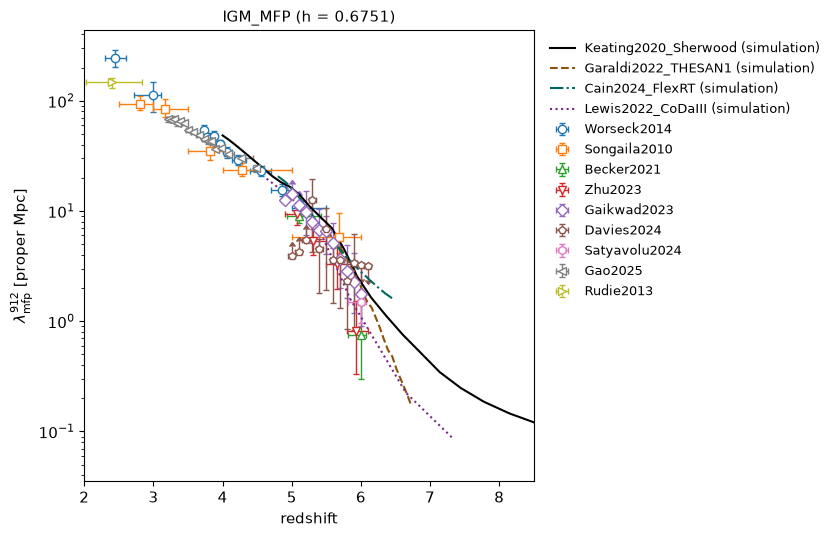

In [6]:
plot_feature('IGM_MFP', r'$\lambda_{\rm mfp}^{912}$ [proper Mpc]', yscale='log', xlim=(2, 8.5));

## IGM temperature at the mean density

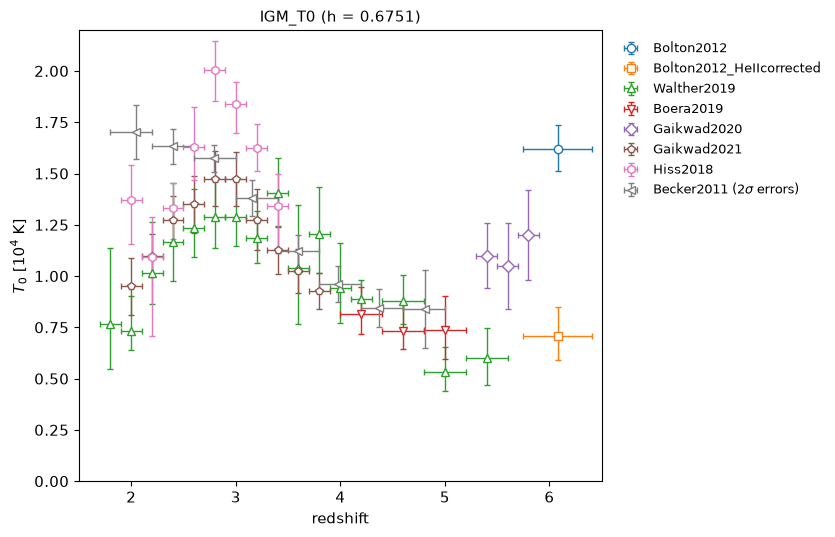

In [7]:
plot_feature('IGM_T0', r'$T_0$ [$10^4$ K]', yfactor=1e-4, xlim=(1.5, 6.5), ylim=(0, 2.2));